# Volatility-timing horse race

This notebook compares lagged realized variance, expanding AR(1), and expanding monthly GARCH(1,1) timing. Lagged RV is last month's sum of demeaned squared daily returns. AR(1) forecasts log monthly RV from an expanding window after 120 observed months and applies the lognormal bias correction. GARCH(1,1) is refit each month to all daily returns available through the preceding month-end; its nonnegative parameters are otherwise unrestricted, including persistence. All three weights are fixed before the target month's factor return. All reported t-statistics use monthly Newey–West standard errors with 12 lags.

In [1]:
# 0. Libraries and project modules
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from config import FACTORS, HAC_LAGS, MANAGED_FACTORS
from data import load_processed_panel
from plots import plot_volatility_estimates
from utils import format_estimate_with_t
from volatility_horse_race import (
    common_horse_race_sample,
    original_factor_spanning_table,
    pairwise_managed_spanning_table,
    subperiod_original_spanning_table,
    volatility_performance_table,
    volatility_summary_table,
)

In [2]:
# 1. Load and validate the processed panel
panel = load_processed_panel(MANAGED_FACTORS, FACTORS)
required = []
for factor in FACTORS:
    required.extend([
        f'rv_{factor}_lag1', f'rv_forecast_ar1_{factor}',
        f'rv_forecast_garch_{factor}', f'managed_ar1_{factor}',
        f'managed_garch_{factor}',
    ])
missing = sorted(set(required) - set(panel.columns))
if missing:
    raise ValueError(f'Missing horse-race columns: {missing}')
common_sample = common_horse_race_sample(panel, FACTORS)
print(
    f'Common horse-race sample: {common_sample.date.min():%Y-%m} to '
    f'{common_sample.date.max():%Y-%m} ({len(common_sample):,} months).'
)

Common horse-race sample: 1973-07 to 2026-07 (637 months).


## 2. Volatility estimates

Stored monthly variances are converted to monthly volatility percentages. Within each factor, all three lines use their common available sample. Lagged realized volatility is known at the start of the return month; AR(1) and GARCH use information available through the preceding month.

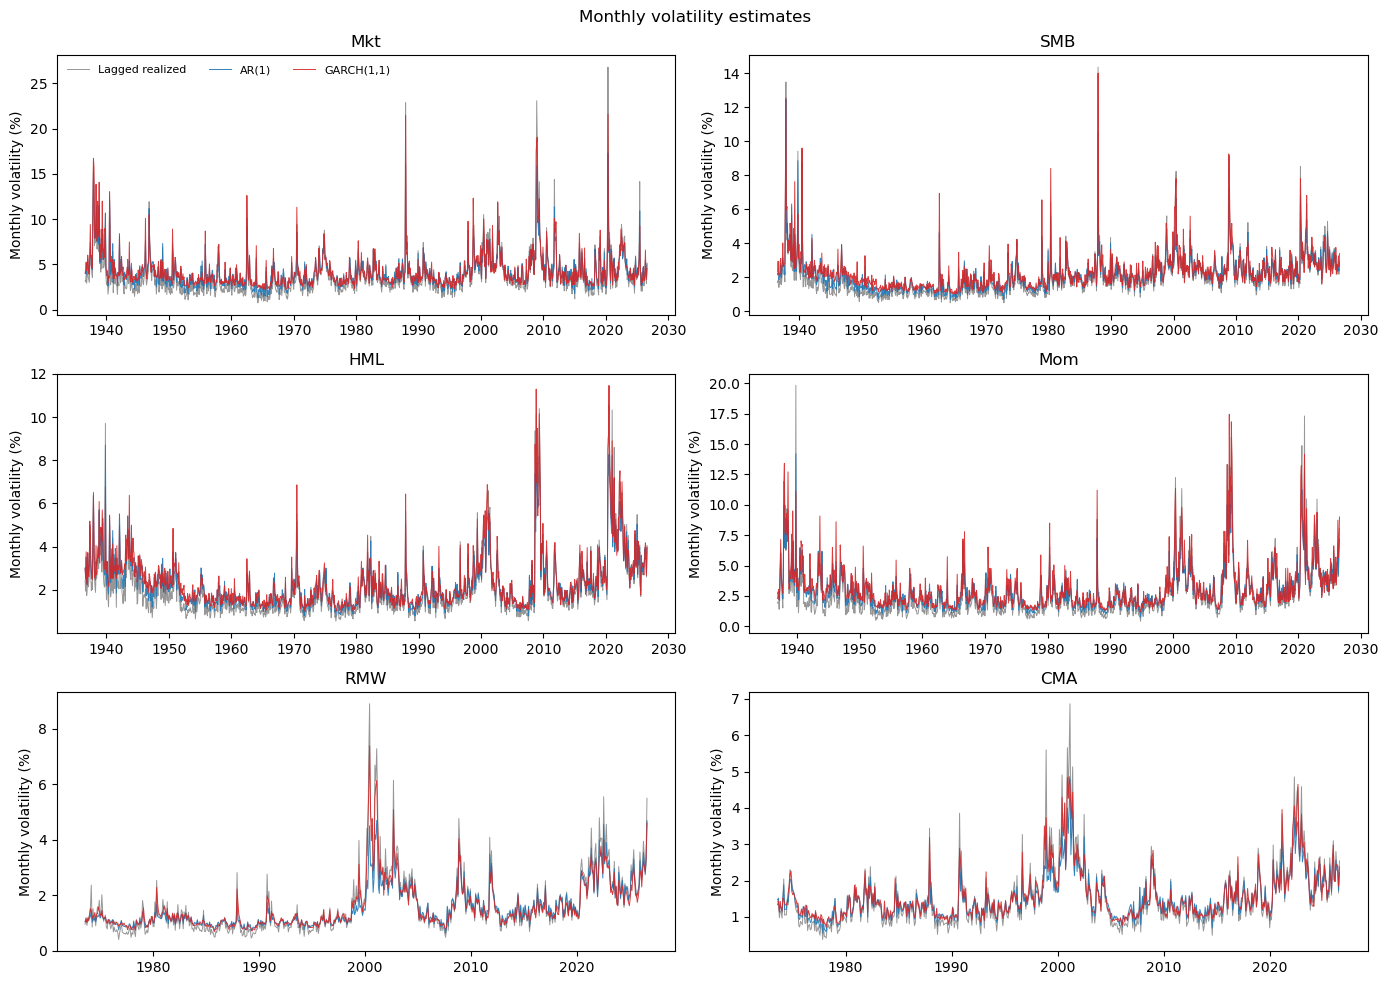

In [3]:
plot_volatility_estimates(panel, FACTORS);

### Volatility summary statistics

The table summarizes the three monthly volatility definitions over the global horse-race sample. All entries are monthly percentage volatility.

In [4]:
volatility_summary = volatility_summary_table(panel, FACTORS)
display(volatility_summary.round(3))

,factor,method,mean_monthly_vol_pct,std_monthly_vol_pct,median_monthly_vol_pct,p95_monthly_vol_pct
0,Mkt,Lagged RV,4.139,2.510,3.494,8.196
1,Mkt,AR(1),4.367,1.758,3.958,7.419
2,Mkt,"GARCH(1,1)",4.429,2.115,3.801,7.809
3,SMB,Lagged RV,2.320,1.111,2.110,3.993
4,SMB,AR(1),2.419,0.860,2.279,3.771
5,SMB,"GARCH(1,1)",2.529,1.102,2.275,4.117
6,HML,Lagged RV,2.257,1.612,1.723,5.548
7,HML,AR(1),2.345,1.274,1.951,5.020
8,HML,"GARCH(1,1)",2.473,1.504,1.969,5.434
9,Mom,Lagged RV,2.905,2.266,2.242,7.222


## 3. Return performance

Only the three volatility-managed versions enter the performance horse race. Every factor and method uses one global common sample. Mean, standard deviation, and alphas are monthly percentages; the Sharpe ratio is annualized. Parentheses contain t-statistics based on Newey–West standard errors with 12 lags. Returns retain their existing construction scale; no ex-post equal-volatility rescaling is imposed here.

In [5]:
performance = volatility_performance_table(panel, FACTORS, HAC_LAGS)
performance_display = pd.DataFrame({
    'Factor': performance['factor'],
    'Method': performance['method'],
    'N': performance['observations'],
    'Monthly mean (%) [NW t]': format_estimate_with_t(
        performance, 'mean_monthly_pct', 'mean_t_nw12'),
    'Monthly std (%)': performance['std_monthly_pct'].map(
        lambda value: f'{value:.3f}'),
    'Annualized SR': performance['annualized_sharpe'].map(lambda value: f'{value:.3f}'),
    'Monthly CAPM alpha (%) [NW t]': format_estimate_with_t(
        performance, 'capm_alpha_monthly_pct', 'capm_alpha_t_nw12'),
    'Monthly FF3 alpha (%) [NW t]': format_estimate_with_t(
        performance, 'ff3_alpha_monthly_pct', 'ff3_alpha_t_nw12'),
    'Monthly FF5 alpha (%) [NW t]': format_estimate_with_t(
        performance, 'ff5_alpha_monthly_pct', 'ff5_alpha_t_nw12'),
})
factor_order = ['Mkt', 'SMB', 'HML', 'RMW', 'CMA', 'Mom']
for table_number, factor_label in enumerate(factor_order, 1):
    display(Markdown(f'### Performance table {table_number}: {factor_label}'))
    display(
        performance_display.loc[
            performance_display['Factor'].eq(factor_label)
        ].drop(columns='Factor').reset_index(drop=True)
    )

### Performance table 1: Mkt

,Method,N,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Lagged RV,637,0.605 (3.44),4.109,0.510,0.183 (1.38),0.190 (1.40),0.133 (0.98)
1,AR(1),637,1.975 (3.76),12.826,0.534,0.461 (1.41),0.493 (1.44),0.331 (0.98)
2,"GARCH(1,1)",637,1.712 (3.59),11.584,0.512,0.316 (1.20),0.352 (1.26),0.204 (0.73)


### Performance table 2: SMB

,Method,N,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Lagged RV,637,0.122 (1.14),1.908,0.221,0.071 (0.66),0.041 (0.55),0.026 (0.36)
1,AR(1),637,0.478 (1.14),8.048,0.206,0.237 (0.56),0.112 (0.44),0.067 (0.27)
2,"GARCH(1,1)",637,0.304 (0.81),7.897,0.133,0.047 (0.12),-0.086 (-0.39),-0.145 (-0.63)


### Performance table 3: HML

...

,Method,N,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Lagged RV,637,0.337 (3.50),1.898,0.615,0.343 (3.58),0.383 (3.91),0.246 (3.11)
1,AR(1),637,0.186 (2.98),1.215,0.530,0.197 (3.16),0.221 (3.52),0.107 (2.54)
2,"GARCH(1,1)",637,0.221 (3.07),1.402,0.545,0.233 (3.23),0.265 (3.65),0.141 (2.74)


### Performance table 5: CMA

,Method,N,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Lagged RV,637,0.224 (2.93),1.770,0.438,0.274 (3.51),0.174 (2.64),0.109 (2.06)
1,AR(1),637,0.237 (2.96),1.758,0.467,0.301 (3.78),0.185 (2.84),0.096 (2.20)
2,"GARCH(1,1)",637,0.275 (2.96),2.027,0.471,0.344 (3.75),0.210 (2.72),0.107 (2.10)


### Performance table 6: Mom

,Method,N,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t]
0,Lagged RV,637,1.223 (5.10),4.319,0.981,1.207 (5.20),1.258 (5.51),1.210 (5.15)
1,AR(1),637,5.292 (5.49),18.645,0.983,5.301 (5.67),5.626 (6.11),5.334 (5.47)
2,"GARCH(1,1)",637,4.287 (5.65),15.697,0.946,4.314 (5.80),4.612 (6.28),4.319 (5.57)


## 4. Spanning by the original factor

Each managed return is regressed on its corresponding original factor. A nonzero intercept indicates that the original factor does not span the managed version. Every regression uses the global sample stated at the beginning. Reported loadings reflect the strategies' stored normalization constants as well as their timing behavior, so loading differences should not be interpreted as pure timing effects.

In [6]:
original_spanning = original_factor_spanning_table(panel, FACTORS, HAC_LAGS)
original_spanning_display = pd.DataFrame({
    'Factor': original_spanning['factor'],
    'Managed method': original_spanning['managed_method'],
    'Alpha (NW t)': format_estimate_with_t(original_spanning, 'alpha_monthly_pct', 'alpha_t_nw12'),
    'Original loading (NW t)': format_estimate_with_t(original_spanning, 'original_factor_loading', 'loading_t_nw12'),
    'R²': original_spanning['r_squared'].map(lambda value: f'{value:.3f}'),
})
display(original_spanning_display)

,Factor,Managed method,Alpha (NW t),Original loading (NW t),R²
0,Mkt,Lagged RV,0.183 (1.38),0.635 (9.68),0.502
1,Mkt,AR(1),0.461 (1.41),2.275 (12.20),0.663
2,Mkt,"GARCH(1,1)",0.316 (1.20),2.097 (12.02),0.691
3,SMB,Lagged RV,0.052 (0.72),0.481 (6.39),0.576
4,SMB,AR(1),0.157 (0.63),2.218 (7.59),0.687
5,SMB,"GARCH(1,1)",-0.005 (-0.03),2.136 (6.47),0.662
6,HML,Lagged RV,0.097 (0.71),0.678 (6.26),0.364
7,HML,AR(1),0.477 (0.79),3.927 (7.34),0.486
8,HML,"GARCH(1,1)",0.700 (1.15),4.539 (7.34),0.528
9,Mom,Lagged RV,0.950 (4.83),0.492 (5.34),0.249


## 5. Spanning among managed factors

The requested pairwise tests use one managed return at a time as the spanning factor: lagged RV on AR(1), lagged RV on GARCH(1,1), and AR(1) on GARCH(1,1). A nonzero intercept indicates that the dependent managed return is not spanned by that single alternative.

In [7]:
managed_spanning = pairwise_managed_spanning_table(panel, FACTORS, HAC_LAGS)
managed_spanning_display = pd.DataFrame({
    'Factor': managed_spanning['factor'],
    'Dependent method': managed_spanning['dependent_method'],
    'Spanning method': managed_spanning['spanning_method'],
    'Alpha (NW t)': format_estimate_with_t(managed_spanning, 'alpha_monthly_pct', 'alpha_t_nw12'),
    'Spanning loading (NW t)': format_estimate_with_t(managed_spanning, 'spanning_loading', 'loading_t_nw12'),
    'R²': managed_spanning['r_squared'].map(lambda value: f'{value:.3f}'),
})
display(managed_spanning_display)

,Factor,Dependent method,Spanning method,Alpha (NW t),Spanning loading (NW t),R²
0,Mkt,Lagged RV,AR(1),-0.016 (-0.41),0.314 (35.38),0.963
1,Mkt,Lagged RV,"GARCH(1,1)",0.035 (0.52),0.333 (23.19),0.882
2,Mkt,AR(1),"GARCH(1,1)",0.122 (1.07),1.083 (48.69),0.956
3,SMB,Lagged RV,AR(1),0.009 (0.76),0.235 (53.25),0.984
4,SMB,Lagged RV,"GARCH(1,1)",0.051 (1.64),0.231 (27.10),0.916
5,SMB,AR(1),"GARCH(1,1)",0.177 (1.91),0.990 (39.69),0.944
6,HML,Lagged RV,AR(1),-0.025 (-0.89),0.197 (36.24),0.976
7,HML,Lagged RV,"GARCH(1,1)",-0.048 (-0.82),0.169 (20.74),0.886
8,HML,AR(1),"GARCH(1,1)",-0.153 (-0.80),0.878 (35.34),0.946
9,Mom,Lagged RV,AR(1),0.038 (1.33),0.224 (23.58),0.934


## 6. Conclusions

- The volatility definition does not materially change the broad cross-factor ranking: the three methods generally produce similar qualitative performance and usually span one another in the requested pairwise tests. The exceptions are lagged-RV momentum relative to GARCH, and lagged-RV RMW relative to AR(1) or GARCH.
- Volatility timing is most robust for momentum. All three momentum specifications have significant full-sample own-factor alpha and remain significant in all three subperiods, although the alpha magnitude is much smaller after November 2008.
- The evidence is generally more favorable before the post-GFC period, but this is not universal across factors. RMW loses its own-factor alpha after November 2008, while Mkt shows significant alpha only in the middle subperiod. SMB, HML, and CMA provide little robust own-factor spanning evidence.
- Original-factor loadings differ visibly between lagged RV and the forecast-based methods. These levels are not directly comparable as pure timing effects because the methods use different stored normalization constants. The loading differences therefore combine normalization, average exposure, and timing behavior and should not determine model choice without an equal-volatility robustness comparison.

## 7. Subperiod original-factor spanning

As a transparency check, the global sample is divided chronologically into three nearly equal numbers of monthly observations. Within each subperiod, each managed return is regressed only on its original counterpart. Entries report monthly alpha with the Newey–West(12) t-statistic in parentheses. The breakpoints are mechanical and were not selected from the results.

In [8]:
subperiod_spanning = subperiod_original_spanning_table(
    panel, FACTORS, HAC_LAGS, periods=3
)
subperiod_spanning['Alpha (NW t)'] = format_estimate_with_t(
    subperiod_spanning, 'alpha_monthly_pct', 'alpha_t_nw12'
)
subperiod_display = subperiod_spanning.pivot(
    index=['factor', 'managed_method'], columns='period', values='Alpha (NW t)'
).reset_index()
display(subperiod_display)

period,factor,managed_method,1973-07 to 1991-03,1991-04 to 2008-11,2008-12 to 2026-07
0,CMA,AR(1),0.092 (1.65),-0.017 (-0.29),-0.017 (-0.30)
1,CMA,"GARCH(1,1)",0.082 (1.40),-0.013 (-0.17),0.010 (0.12)
2,CMA,Lagged RV,0.135 (1.78),-0.016 (-0.24),-0.015 (-0.23)
3,HML,AR(1),0.177 (0.20),0.557 (0.45),-0.515 (-1.23)
4,HML,"GARCH(1,1)",-0.028 (-0.03),1.123 (1.04),-0.340 (-0.57)
5,HML,Lagged RV,0.056 (0.27),0.090 (0.30),-0.104 (-1.32)
6,Mkt,AR(1),0.042 (0.10),1.243 (2.21),0.415 (0.64)
7,Mkt,"GARCH(1,1)",-0.140 (-0.42),0.856 (1.81),0.592 (1.24)
8,Mkt,Lagged RV,0.020 (0.13),0.495 (2.16),0.123 (0.44)
9,Mom,AR(1),4.588 (3.93),3.785 (3.86),1.282 (2.62)
